# Figure 4 — UMAP expression scatter plots (Dinoflagellata)

Standalone script for manuscript code availability. Produces two UMAP scatter plots:

1. **% Viral UMIs** — fraction of UMIs mapping to viral genes per cell
2. **Normalized viperin expression** — log-normalized expression of putative viperin (`140101_m_AIL3`)

Requires a preprocessed AnnData object with `X_umap`, `layers['counts']`, and `layers['lognorm']`.

In [36]:
import os
from pathlib import Path
from typing import Iterable, List, Optional, Sequence, Set, Tuple, Union

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp


def read_emapper_annotations(path: Union[str, Path]) -> pd.DataFrame:
    """Load eggNOG-mapper annotation file (.emapper.annotations)."""
    header = None
    skiprows: List[int] = []
    with Path(path).open() as handle:
        for idx, line in enumerate(handle):
            if line.startswith("##"):
                skiprows.append(idx)
            elif line.startswith("#query"):
                header = line.lstrip("#").strip().split("\t")
                skiprows.append(idx)
                break
    if header is None:
        raise ValueError(f"No #query header line found in {path}")
    return pd.read_csv(
        path,
        sep="\t",
        names=header,
        skiprows=skiprows,
        dtype=str,
        low_memory=False,
    )


def get_viral_genes(
    path_viral_list: Union[str, Path],
    path_eggnog: Union[str, Path],
    path_blast: Union[str, Path],
    blast_min_pident: float = 90.0,
    blast_min_length: int = 100,
) -> Set[str]:
    """Union of viral gene IDs from list, eggNOG Viruses OG, and BLAST hits."""
    with Path(path_viral_list).open() as handle:
        viral_genes = [line.rstrip("\n") for line in handle if line.strip()]
    eggnog = read_emapper_annotations(path_eggnog)
    blast_data = pd.read_table(
        path_blast,
        sep="\t",
        names=(
            "qseqid sseqid pident length mismatch gapopen qstart qend "
            "sstart send evalue bitscore"
        ).split(),
    )
    viral_genes_from_genome = blast_data.loc[
        (blast_data["pident"] >= blast_min_pident)
        & (blast_data["length"] >= blast_min_length),
        "sseqid",
    ].unique()
    viral_subset = eggnog[eggnog["eggNOG_OGs"].str.contains("Viruses", na=False)]
    viral_genes_eggnog = viral_subset["query"].unique()
    return set(map(str, list(viral_genes_eggnog) + viral_genes + list(viral_genes_from_genome)))


def _to_dense(column) -> np.ndarray:
    if sp.issparse(column):
        return np.asarray(column.sum(axis=1)).ravel()
    arr = np.asarray(column)
    if arr.ndim == 2:
        return arr.sum(axis=1).ravel()
    return arr.ravel()


def gene_expression(
    adata,
    genes: Sequence[str],
    *,
    fraction: bool = False,
    raw: bool = False,
    log: bool = False,
    colorbar_label: Optional[str] = None,
    figsize: Tuple[float, float] = (4, 4),
    save_path: Optional[Union[str, Path]] = None,
    show: bool = True,
):
    """Color UMAP by summed gene expression or viral UMI fraction."""
    present = [g for g in genes if g in adata.var_names]
    if not present:
        raise ValueError(f"None of {genes} found in adata.var_names.")

    gene_idx = adata.var_names.get_indexer(present)

    if fraction:
        if "counts" not in adata.layers:
            raise ValueError("fraction=True requires adata.layers['counts'].")
        counts = adata.layers["counts"]
        selected = _to_dense(counts[:, gene_idx])
        total = _to_dense(counts)
        with np.errstate(divide="ignore", invalid="ignore"):
            values = 100.0 * selected / total
        obs_key = "viral_umi_fraction"
    else:
        layer = "counts" if raw else "lognorm"
        if layer not in adata.layers:
            raise ValueError(f"Missing adata.layers[{layer!r}].")
        values = _to_dense(adata.layers[layer][:, gene_idx])
        obs_key = "gene_score_raw" if raw else "gene_score_lognorm"

    if log:
        values = np.log1p(values)

    values = np.where(values <= 0, np.nan, values)
    adata.obs[obs_key] = values

    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    sc.pl.umap(
        adata,
        color=obs_key,
        cmap="inferno",
        ax=ax,
        size=50,
        show=False,
    )
    ax.set_title("")
    if colorbar_label and ax.collections:
        ax.collections[0].colorbar.set_label(colorbar_label, rotation=270, labelpad=25)

    if save_path:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, bbox_inches="tight")

    if show:
        plt.show()
    else:
        plt.close(fig)
    return fig, ax

In [39]:
# --- configuration ---
taxonomy = "Dinoflagellata"
data_file = f"/home/labs/vardi/amirz/pairing/Alps_All_MetaG/Alps_preprocessed_{taxonomy}.h5ad"
path_output = "/home/labs/vardi/amirz/pairing/Alps_All_MetaG/gene_expression/"

eggnog_file = (
    "/home/labs/vardi/Collaboration/databases/Gossenkollesee/MetaG_eggnog/"
    "MetaG_eggnog.emapper.annotations"
)
path_viral_list = (
    "/home/labs/vardi/Collaboration/databases/Gossenkollesee/"
    "mapped_cells_virus/viral_genes.list"
)
path_blast = (
    "/home/labs/vardi/amirz/pairing/Alps_All_MetaG/gene_expression/AIL3.53_METAG.tsv"
)

viperin_gene = "140101_m_AIL3"
figsize = (4, 2.5)

viral_umis_png = os.path.join(path_output, f"umap_viral_umis.{taxonomy}.png")
viperin_png = os.path.join(path_output, f"umap_viperin.{taxonomy}.png")

### Load data and viral gene set

In [28]:
adata = sc.read_h5ad(data_file)
viral_genes = get_viral_genes(path_viral_list, eggnog_file, path_blast)
viral_genes_in_matrix = sorted(set(viral_genes) & set(map(str, adata.var_names)))
print(f"Cells: {adata.n_obs:,}")
print(f"Viral genes in matrix: {len(viral_genes_in_matrix):,} / {len(viral_genes):,}")
print(f"Viperin present: {viperin_gene in adata.var_names}")

Cells: 372
Viral genes in matrix: 153 / 6,331
Viperin present: True


### UMAP colored by % Viral UMIs

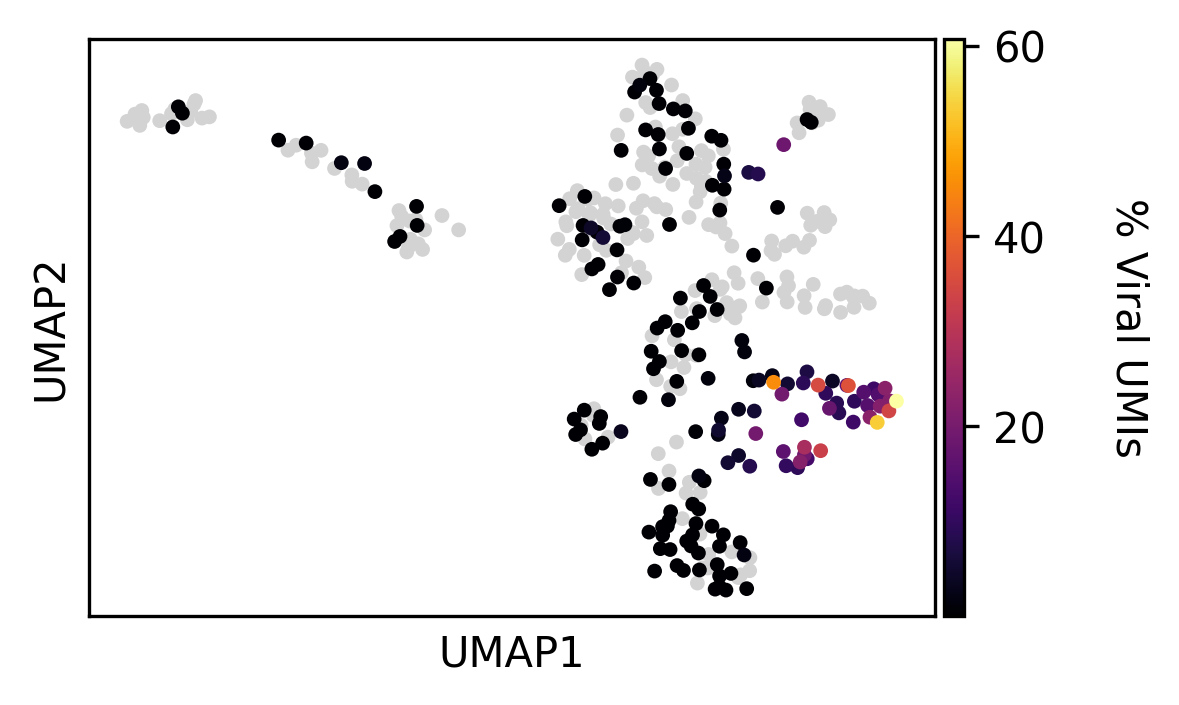

(<Figure size 1200x750 with 2 Axes>, <Axes: xlabel='UMAP1', ylabel='UMAP2'>)

In [40]:
gene_expression(
    adata,
    viral_genes_in_matrix,
    fraction=True,
    colorbar_label="% Viral UMIs",
    figsize=figsize,
    save_path=viral_umis_png,
)

### UMAP colored by normalized viperin expression

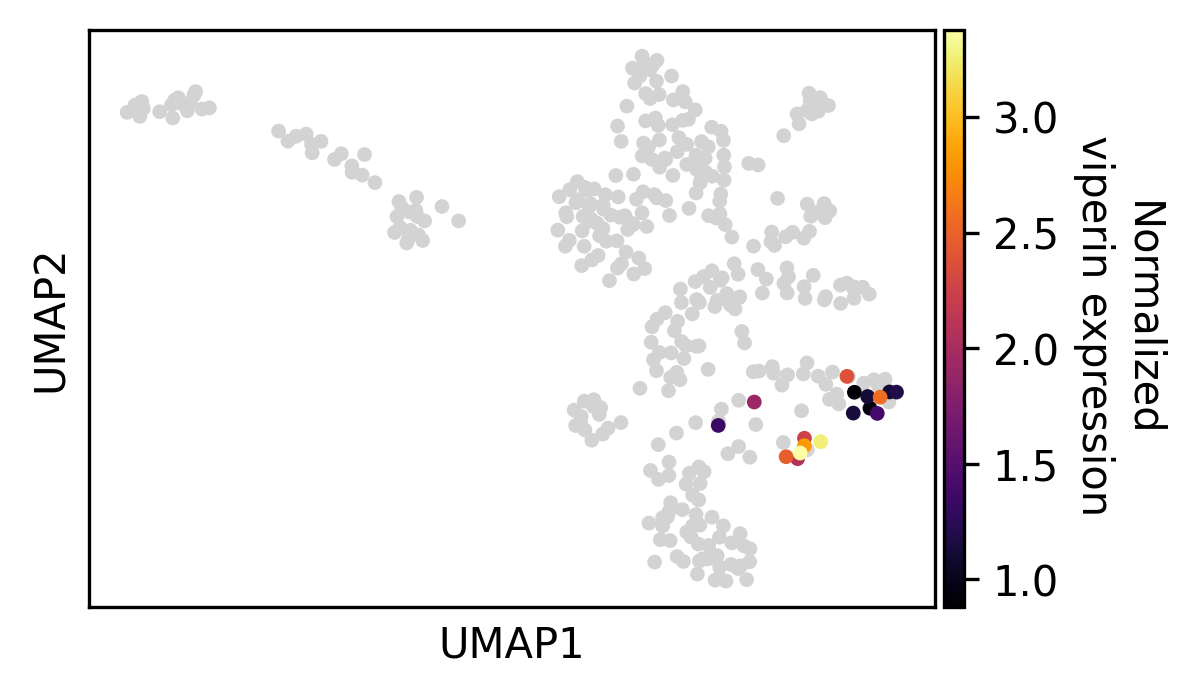

(<Figure size 1200x750 with 2 Axes>, <Axes: xlabel='UMAP1', ylabel='UMAP2'>)

In [41]:
gene_expression(
    adata,
    [viperin_gene],
    fraction=False,
    raw=False,
    colorbar_label="Normalized\n viperin expression",
    figsize=figsize,
    save_path=viperin_png,
)